## Interpretable Deep Learning for Single-Cell RNA-seq Classification
## Project objective
- Investiagating whether machine-learning models can classify immune-cell types from single-cell RNA sequencing (scRNA-seq) data while generalising across experimental batches.
- A Logistic Regression model will be used as a baseline and compared with a feed-forward neural network implemented in PyTorch
- The neural network will be interpreted using Integrated Gradients to investigate which genes contribute most strongly to individual cell-type predictions.
##  Research questions
1. Can cell types be classified accurately from single-cell gene-expression profiles?
2. Does a neural network improve upon a strong classical machine-learning baseline?
3. Do the models generalise to cells from a different experimental batch?
4. Are the neural network's predictions driven by biologically meaningful gene features?

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc
import scvi
import torch
from importlib.metadata import version

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

print("PyTorch:", torch.__version__)
print("Scanpy:", version("scanpy"))
print("scvi-tools:", version("scvi-tools"))

PyTorch: 2.14.0+cpu
Scanpy: 1.11.5
scvi-tools: 1.4.2


## Dataset Information
The analysis uses a publically available dataset containing peripheral blood mononuclear clear (PBMC) single-cell RNA-seq

In the expression matrix:
- each row represents an individual cell
- each column represents a gene
- each value represents the measured expression of that gene in that cell

In [5]:
adata = scvi.data.pbmc_dataset()
adata

INFO     File data/gene_info_pbmc.csv already downloaded                                                           
INFO     File data/pbmc_metadata.pickle already downloaded                                                         
INFO     File data/pbmc8k/filtered_gene_bc_matrices.tar.gz already downloaded                                      
INFO     Extracting tar file                                                                                       
INFO     Removing extracted data at data/pbmc8k/filtered_gene_bc_matrices                                          
INFO     File data/pbmc4k/filtered_gene_bc_matrices.tar.gz already downloaded                                      
INFO     Extracting tar file                                                                                       
INFO     Removing extracted data at data/pbmc4k/filtered_gene_bc_matrices                                          


/home/fionnualamoody/projects/single-cell-interpretable-ml/.venv/lib/python3.11/site-packages/scvi/data/_built_in_data/_pbmc.py:75: FutureWarning: The method concatenate is deprecated and will be removed in the future. Use anndata.concat instead of AnnData.concatenate. See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  adata = pbmc8k.concatenate(pbmc4k)


AnnData object with n_obs × n_vars = 11990 × 3346
    obs: 'n_counts', 'batch', 'labels', 'str_labels'
    var: 'gene_symbols', 'n_counts-0', 'n_counts-1', 'n_counts'
    uns: 'cell_types'
    obsm: 'design', 'raw_qc', 'normalized_qc', 'qc_pc'

## Intial data exploration:
Before preprocessing or modelling, going to look at  the structure of the dataset in order to identify if there is class imbalance and design the appropriate train/validation/test strategy

In [6]:
print("Dataset shape:", adata.shape)
print("̣\nCell metadata:")
display(adata.obs.head())
print("\nGene metadata:")
display(adata.var.head())

Dataset shape: (11990, 3346)
̣
Cell metadata:


,n_counts,batch,labels,str_labels
AAACCTGAGCTAGTGG-1,4520.0,0,2,CD4 T cells
AAACCTGCACATTAGC-1,2788.0,0,2,CD4 T cells
AAACCTGCACTGTTAG-1,4667.0,0,1,CD14+ Monocytes
AAACCTGCATAGTAAG-1,4440.0,0,1,CD14+ Monocytes
AAACCTGCATGAACCT-1,3224.0,0,3,CD8 T cells



Gene metadata:


,gene_symbols,n_counts-0,n_counts-1,n_counts
ENSG00000188976,NOC2L,1477.0,718.0,2135.0
ENSG00000187608,ISG15,4014.0,1888.0,5705.0
ENSG00000149527,PLCH2,121.0,41.0,157.0
ENSG00000157881,PANK4,224.0,107.0,326.0
ENSG00000157873,TNFRSF14,3639.0,1683.0,5193.0


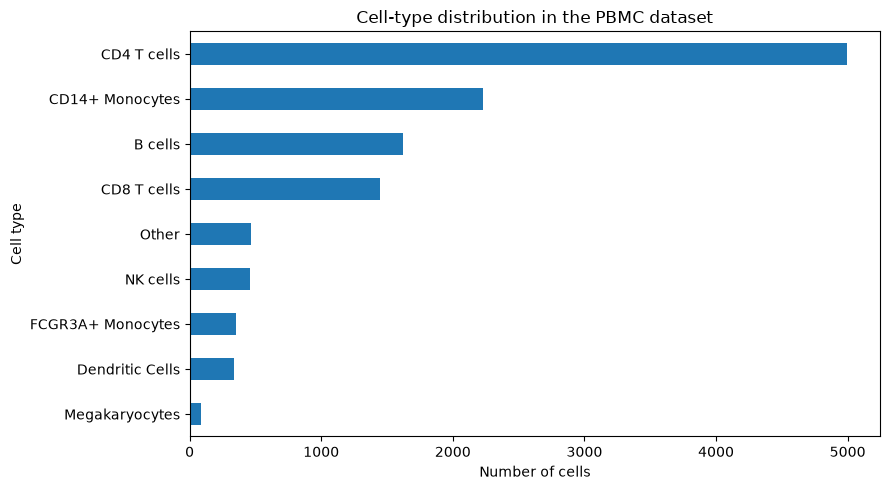

In [7]:
# Look at cell types
cell_counts= (
    adata.obs["str_labels"]
    .value_counts()
    .sort_values(ascending=False)
)
cell_counts
plt.figure(figsize=(9,5))
cell_counts.sort_values().plot(kind="barh")
plt.xlabel("Number of cells")
plt.ylabel("Cell type")
plt.title("Cell-type distribution in the PBMC dataset")
plt.tight_layout()
plt.show()

In [8]:
# Exploring the batches
print("Cells per batch:")
display(adata.obs["batch"].value_counts())
print("\nCell types by batch:")

batch_table = pd.crosstab(
    adata.obs["str_labels"],
    adata.obs["batch"]
)
display(batch_table)

Cells per batch:


batch
0    7982
1    4008
Name: count, dtype: int64


Cell types by batch:


batch,0,1
str_labels,,
B cells,1060,561
CD14+ Monocytes,1483,744
CD4 T cells,3364,1632
CD8 T cells,948,500
Dendritic Cells,209,130
FCGR3A+ Monocytes,224,127
Megakaryocytes,63,25
NK cells,285,172
Other,346,117


## Next steps:
- Batch 1 will be kept for a test set
- Batch 0 will be divided into training and validation subsets.


In [9]:
from sklearn.model_selection import train_test_split

batch_values = adata.obs["batch"].astype(str)

batch0_names = adata.obs_names[batch_values == "0"]
batch1_names = adata.obs_names[batch_values == "1"]

batch0_labels = adata.obs.loc[batch0_names, "str_labels"]

# using stratify so that the train and val subsets keep around  the same class proportions
train_names, val_names = train_test_split(
    batch0_names,
    test_size = 0.20,
    random_state = SEED,
    stratify = batch0_labels
)

test_names = batch1_names

train = adata[train_names].copy()
val = adata[val_names].copy()
test = adata[test_names].copy()

print("Training set:", train.shape)
print("Validation set:", val.shape)
print("Test set:", test.shape)

Training set: (6385, 3346)
Validation set: (1597, 3346)
Test set: (4008, 3346)


## Preprocessing
- Preprocessing will be performed to avoid information leakage, gene filtering and highly variable gene selection. These genes are applied to the validation and test sets.

In [13]:
from scipy.sparse import issparse

X_sample = train.X[:10, :10]

if issparse(X_sample):
    X_sample = X_sample.toarray()

print(X_sample)
print("\nMinimum:", X_sample.min())
print("Maximum:", X_sample.max())

# testing larger section of matrix
X_check = train.X[:100, :100]

if issparse(X_check):
    X_check = X_check.toarray()

print(
    "All sampled values integer-like:",
    np.allclose(X_check, np.round(X_check))
)

[[1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 2. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [1. 1. 0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 2. 0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]

Minimum: 0.0
Maximum: 2.0
All sampled values integer-like: True


## Gene filtering and normalisation

- Removing genes that have been detected in very few cells as they provide little information for classification and can add noise.
- Expression values are normalised per cell to reduce differences in sequencing depth. A log transformation is applied to compress the highly skewed distribution of gene-expression values.
  

In [15]:
#  Filter genes using just the training set
sc.pp.filter_genes(train, min_cells=3)

genes_kept = train.var_names.copy()

# Apply same gene set to the validation and test data
val = val[:, genes_kept].copy()
test = test[:, genes_kept].copy()

print("Training set:", train.shape)
print("Validation set:", val.shape)
print("Test set:", test.shape)

for dataset in [train, val, test]:
    sc.pp.normalize_total(dataset, target_sum=1e4)
    sc.pp.log1p(dataset)

print("Genes after filtering:", train.n_vars)

Training set: (6385, 3346)
Validation set: (1597, 3346)
Test set: (4008, 3346)
Genes after filtering: 3346


## Highly variable gene selection
- Single-cell datasets contain many genes whose expression varies little across cells or contributes limited information for distinguishing cell populations.
- Next the 1000 most highly variable genes are selected using just the training data. The same gene set is applied to the validation and test datasets.


In [17]:
sc.pp.highly_variable_genes(
    train,
    n_top_genes=1000,
    flavor="seurat",
    subset=False
)

hvg_names = train.var_names[train.var["highly_variable"]]

train = train[:, hvg_names].copy()
val = val[:, hvg_names].copy()
test = test[:, hvg_names].copy()

print("Training set:", train.shape)
print("Validation set:", val.shape)
print("Test set:", test.shape)

Training set: (6385, 1000)
Validation set: (1597, 1000)
Test set: (4008, 1000)


## Preparing data for machine learning 

- The preprocessed AnnData expression matrices are converted into NumPy arrays for use with scikit-learn and PyTorch.
- Cell-type labels are encoded numerically and gene-expression features are standardised using statistics learned from just the training set.

In [19]:
from scipy.sparse import issparse

def to_dense_array(adata_object):
    X= adata_object.X

    if issparse(X):
        X = X.toarray()

    return np.asarray(X, dtype=np.float32)

X_train = to_dense_array(train)
X_val = to_dense_array(val)
X_test = to_dense_array(test)

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

X_train: (6385, 1000)
X_val: (1597, 1000)
X_test: (4008, 1000)


In [20]:
# Encode cell-type labels

from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_train = label_encoder.fit_transform(train.obs["str_labels"])
y_val = label_encoder.fit_transform(val.obs["str_labels"])
y_test = label_encoder.fit_transform(test.obs["str_labels"])

label_mapping = pd.DataFrame({
    "Encoded label": range(len(label_encoder.classes_)),
    "Cell type": label_encoder.classes_
})

display(label_mapping)

,Encoded label,Cell type
0,0,B cells
1,1,CD14+ Monocytes
2,2,CD4 T cells
3,3,CD8 T cells
4,4,Dendritic Cells
5,5,FCGR3A+ Monocytes
6,6,Megakaryocytes
7,7,NK cells
8,8,Other


## Standardise the gene features

- Gene expression features are standardised to reduce differences in numerical scale between genes.
- The scaler is fitted using the training data only. The training means and standard deviations are applied to the validation and test sets so to prevent information leakage. 

In [25]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Training mean:", X_train_scaled.mean())
print("Training standard deviation:", X_train_scaled.std())

Training mean: 5.400918e-10
Training standard deviation: 1.0


In [26]:
# Quick check
print("Feature matrices:")
print("Train:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Test:", X_test_scaled.shape)

print("\nLabel vectors:")
print("Train:", y_train.shape)
print("Validation:", y_val.shape)
print("Test:", y_test.shape)

print("\nNumber of classes:", len(label_encoder.classes_))

Feature matrices:
Train: (6385, 1000)
Validation: (1597, 1000)
Test: (4008, 1000)

Label vectors:
Train: (6385,)
Validation: (1597,)
Test: (4008,)

Number of classes: 9


## Logistic Regression 
- Using a logistic regression classifier as a baseline.
- LR can work well on high dimensional gene-expression data and provide a useful benchmark to compare the neural network.
- Balanced class weights as used due to the cell type classed being imbalanced.
- Performance will be evaluated using overall accuracy and macro-averaged F1-score.

In [29]:
#Train baseline model
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import(
    accuracy_score,
    f1_score,
    classification_report
)

baseline_model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state= SEED
)

baseline_model.fit(X_train_scaled, y_train)

# evaluate on validation data
val_predictions = baseline_model.predict(X_val_scaled)
val_accuracy = accuracy_score(y_val, val_predictions)
val_macro_f1 = f1_score(
    y_val,
    val_predictions,
    average = "macro"
)

print("Validation results")
print(f"Accuracy: {val_accuracy:.4f}")
print(f"Macro F1: {val_macro_f1:.4f}")

print(
    classification_report(
        y_val,
        val_predictions,
        target_names = label_encoder.classes_
    )
)

Validation results
Accuracy: 0.9580
Macro F1: 0.9063
                   precision    recall  f1-score   support

          B cells       0.99      1.00      1.00       212
  CD14+ Monocytes       0.95      0.99      0.97       297
      CD4 T cells       0.97      0.98      0.98       673
      CD8 T cells       0.92      0.91      0.91       190
  Dendritic Cells       0.97      0.88      0.93        42
FCGR3A+ Monocytes       0.93      0.87      0.90        45
   Megakaryocytes       0.80      0.67      0.73        12
         NK cells       0.91      0.91      0.91        57
            Other       0.90      0.78      0.84        69

         accuracy                           0.96      1597
        macro avg       0.93      0.89      0.91      1597
     weighted avg       0.96      0.96      0.96      1597



- Following the Logistic Regression baseline model, 95.8% validation accuracy was achieved as well as a macro-F1 score of 0.9606.
- Performance was strong across most cell types, although inn  rarer classes such as megakaryocytes there were lower scores.
- The difference between overall accuracy and macro-F1 shows the importance of class-specific evaluation in an imbalanced dataset.


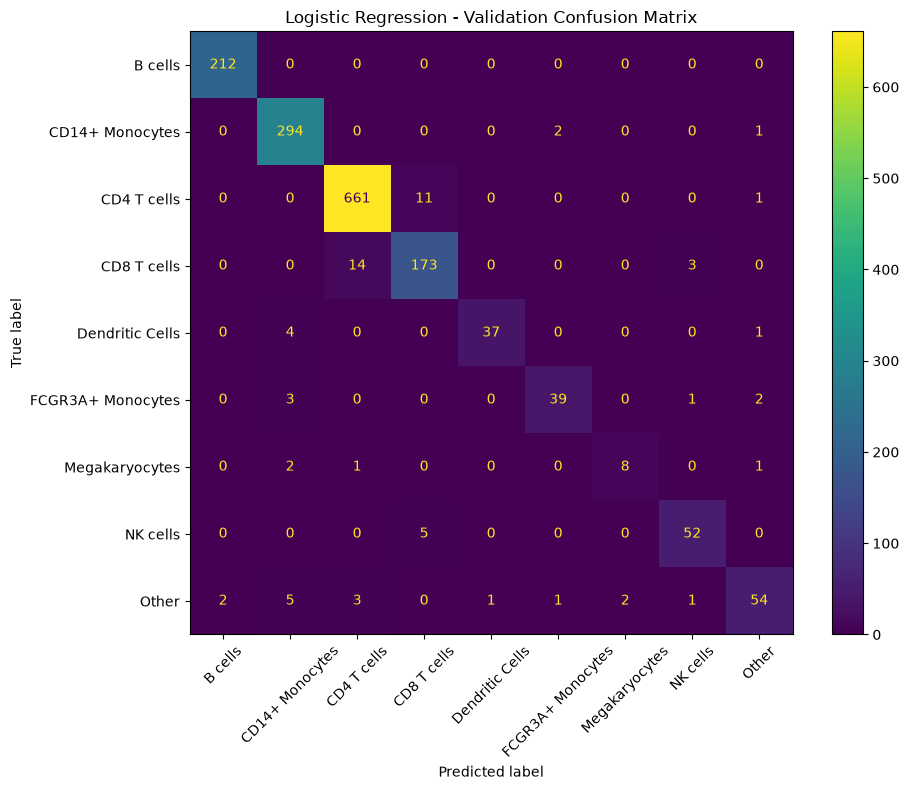

In [32]:
# Validation confusion matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig,ax = plt.subplots(figsize=(10,8))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    val_predictions,
    display_labels=label_encoder.classes_,
    xticks_rotation=45,
    ax=ax
)

ax.set_title("Logistic Regression - Validation Confusion Matrix")
plt.tight_layout()
plt.show()

- There is strong classification across the major cell populations.
- Most of the erros occured between biologicaaly related cell types, especially CD4 and CD8 T cells, CD8 T cells and NK cells, and the two monocyte populations.
- Megakaryocytes had weaker performance, although it only had 12 validation cells.
- The "Other" category showed a broader pattern of missclassification.

In [35]:
# Evaluating LR on "Held-out" experimental batch
test_predictions = baseline_model.predict(X_test_scaled)
test_accuracy = accuracy_score(y_test, test_predictions)

test_macro_f1 = f1_score(
    y_test,
    test_predictions,
    average="macro"
)

print("Held-out test results")
print(f"Accuracy: {test_accuracy:4f}")
print(f"Macro F1: {test_macro_f1:4f}")

print(
    classification_report(
        y_test,
        test_predictions,
        target_names=label_encoder.classes_
    )
)

Held-out test results
Accuracy: 0.949601
Macro F1: 0.919968
                   precision    recall  f1-score   support

          B cells       0.98      0.98      0.98       561
  CD14+ Monocytes       0.94      0.98      0.96       744
      CD4 T cells       0.97      0.97      0.97      1632
      CD8 T cells       0.89      0.90      0.89       500
  Dendritic Cells       0.96      0.90      0.93       130
FCGR3A+ Monocytes       0.95      0.83      0.88       127
   Megakaryocytes       0.88      0.92      0.90        25
         NK cells       0.95      0.95      0.95       172
            Other       0.88      0.76      0.82       117

         accuracy                           0.95      4008
        macro avg       0.93      0.91      0.92      4008
     weighted avg       0.95      0.95      0.95      4008



- The LR model generalised well to the held-out batch as it achieved 95% accuracy and a macro-F1 score of 0.920. Performance was close to the validation results despite the batch shift, however macro-F1 increased slightly.
- Most defined cell populations were classified with highh F1 scores. Lower performance was observed for FCGR3A+ monocytes, CD8 T cells and the "Other" category. This suggests that the model captures cell type associated expression patterns that transfer across the two experimental batches represented in this dataset. 

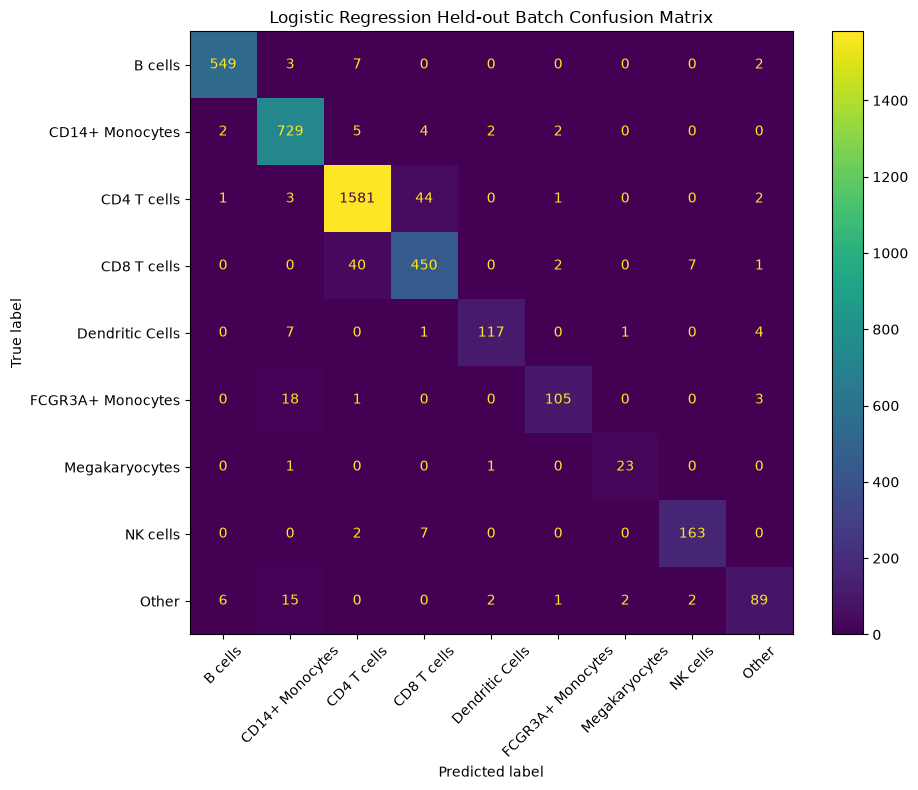

In [36]:
#  Held-out batch test confusion matrix
fig,ax = plt.subplots(figsize=(10,8))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    display_labels=label_encoder.classes_,
    xticks_rotation=45,
    ax=ax
)

ax.set_title("Logistic Regression Held-out Batch Confusion Matrix")
plt.tight_layout()
plt.show()

- The held-out confusion matrix above shows that most classification errors occured between biologically related cell populations. The largest confusion was between CD4 and CD8 T cells, while some FCGR3A+ monocytes were classified as CD14+ monocytes. NK cells also showed limited confusion with CD8 T cells.
- Teh "Other" category showed the broadest spread of misclassifications. While major populations like B cells, CD14+ monocytes and CD4 T cells were classified with high accuracy. Overall the patterns of errors remain biologically plausible on independent experimental batch.